In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
# Load dataset

df = pd.read_csv(r"C:\ML PROJECT\generated_data\segmentation_features.csv")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (2192, 11)

First five rows:


,image_name,tumor_type,tumor_area,tumor_percentage,tumor_width,tumor_height,aspect_ratio,mean_intensity,std_intensity,min_intensity,max_intensity
0,enh_1841.png,Glioma,5973,2.278519,88,85,1.035294,118.261678,63.219609,1,242
1,enh_1842.png,Glioma,6523,2.488327,90,89,1.011236,116.281159,60.558850,1,236
2,enh_1843.png,Glioma,5800,2.212524,86,92,0.934783,114.764138,56.469622,1,236
3,enh_1844.png,Glioma,3352,1.278687,65,61,1.065574,103.958532,44.343451,13,212
4,enh_1845.png,Glioma,9911,3.780746,106,128,0.828125,149.474725,48.307842,1,254



Column names:
['image_name', 'tumor_type', 'tumor_area', 'tumor_percentage', 'tumor_width', 'tumor_height', 'aspect_ratio', 'mean_intensity', 'std_intensity', 'min_intensity', 'max_intensity']


In [3]:
# Separate numerical features and ground-truth labels

X = df.drop(columns=["image_name", "tumor_type"])
y_true = df["tumor_type"]

print("Feature shape:", X.shape)
print("\nGround-truth class distribution:")
print(y_true.value_counts())

# Standardize features for clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nScaled feature shape:", X_scaled.shape)

Feature shape: (2192, 9)

Ground-truth class distribution:
tumor_type
Pituitary tumor    930
Meningioma         708
Glioma             554
Name: count, dtype: int64

Scaled feature shape: (2192, 9)


# K-Means Clustering — Elbow Method

The Elbow Method evaluates K-Means models with different numbers of clusters by comparing their within-cluster sum of squares (inertia). The resulting curve helps identify a suitable number of clusters by locating the point where further reductions in inertia become less pronounced.


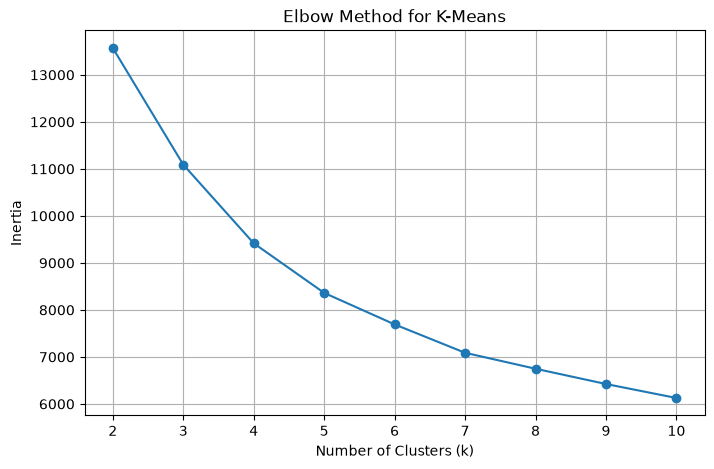

In [4]:
# Elbow Method to select the number of clusters

inertias = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

## K-Means Clustering

Based on the Elbow Method, K-Means is initially configured with four clusters. The model is fitted using the standardized numerical features. The resulting cluster assignments will be evaluated using internal clustering metrics.

In [5]:
kmeans_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

print("K-Means clustering completed.")
print("\nCluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

K-Means clustering completed.

Cluster sizes:
0    497
1    429
2    884
3    382
Name: count, dtype: int64


## K-Means Evaluation Metrics

The K-Means model is evaluated using three internal clustering metrics. The Silhouette Score measures how well samples fit within their assigned clusters compared with other clusters. The Davies–Bouldin Index measures cluster similarity, while the Calinski–Harabasz Index compares between-cluster dispersion with within-cluster dispersion.

A higher Silhouette Score and Calinski–Harabasz Index are generally preferred, whereas a lower Davies–Bouldin Index is preferred.

In [6]:
kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
kmeans_davies_bouldin = davies_bouldin_score(X_scaled, kmeans_labels)
kmeans_calinski_harabasz = calinski_harabasz_score(
    X_scaled, kmeans_labels
)

print("K-Means Evaluation Metrics")
print("-" * 35)
print(f"Silhouette Score: {kmeans_silhouette:.4f}")
print(f"Davies-Bouldin Index: {kmeans_davies_bouldin:.4f}")
print(f"Calinski-Harabasz Index: {kmeans_calinski_harabasz:.4f}")

K-Means Evaluation Metrics
-----------------------------------
Silhouette Score: 0.2468
Davies-Bouldin Index: 1.2790
Calinski-Harabasz Index: 798.4476


## K-Means Visualization Using PCA

Principal Component Analysis (PCA) reduces the standardized feature space to two dimensions while retaining as much variance as possible. The scatter plot displays samples colored by their K-Means cluster assignments. PCA is used only for visualization; K-Means was fitted using all standardized numerical features.

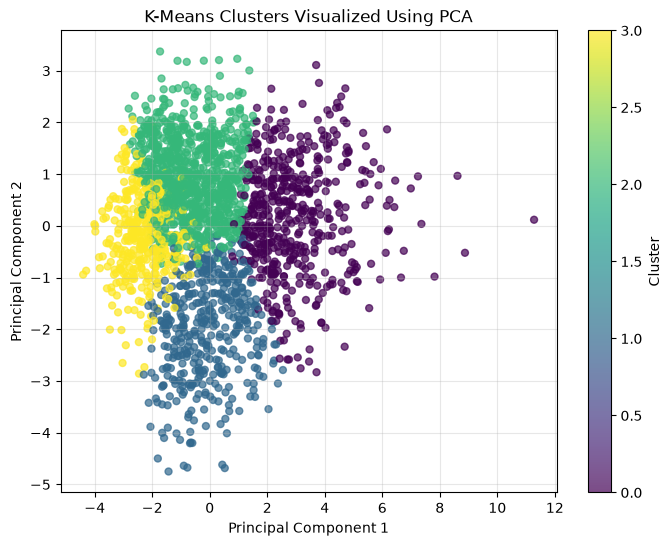

Explained variance by first two components: 68.18%


In [7]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=25,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters Visualized Using PCA")
plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.3)
plt.show()

print(
    "Explained variance by first two components:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

# Agglomerative Hierarchical Clustering

Agglomerative Hierarchical Clustering is a bottom-up clustering method. Initially, each sample forms its own cluster, and the algorithm repeatedly merges clusters according to a linkage criterion until the specified number of clusters is reached.

For this experiment, the number of clusters is set to four to enable comparison with K-Means. The model uses the same standardized numerical features.

In [8]:
agg_model = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward"
)

agg_labels = agg_model.fit_predict(X_scaled)

print("Agglomerative Clustering completed.")
print("\nCluster sizes:")
print(pd.Series(agg_labels).value_counts().sort_index())

Agglomerative Clustering completed.

Cluster sizes:
0    913
1    540
2    466
3    273
Name: count, dtype: int64


## Agglomerative Clustering Evaluation Metrics

The Agglomerative Clustering model is evaluated using the Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index. These metrics assess cluster cohesion and separation without using the ground-truth tumor labels during model fitting.

In [9]:
agg_silhouette = silhouette_score(X_scaled, agg_labels)
agg_davies_bouldin = davies_bouldin_score(X_scaled, agg_labels)
agg_calinski_harabasz = calinski_harabasz_score(
    X_scaled, agg_labels
)

print("Agglomerative Clustering Evaluation Metrics")
print("-" * 45)
print(f"Silhouette Score: {agg_silhouette:.4f}")
print(f"Davies-Bouldin Index: {agg_davies_bouldin:.4f}")
print(f"Calinski-Harabasz Index: {agg_calinski_harabasz:.4f}")

Agglomerative Clustering Evaluation Metrics
---------------------------------------------
Silhouette Score: 0.2156
Davies-Bouldin Index: 1.3366
Calinski-Harabasz Index: 693.3752


## Agglomerative Clustering Visualization Using PCA

PCA reduces the standardized numerical features to two principal components for visualization. Each point is colored according to its Agglomerative cluster assignment. The clustering model itself was fitted using all nine standardized numerical features, not the two-dimensional PCA representation.

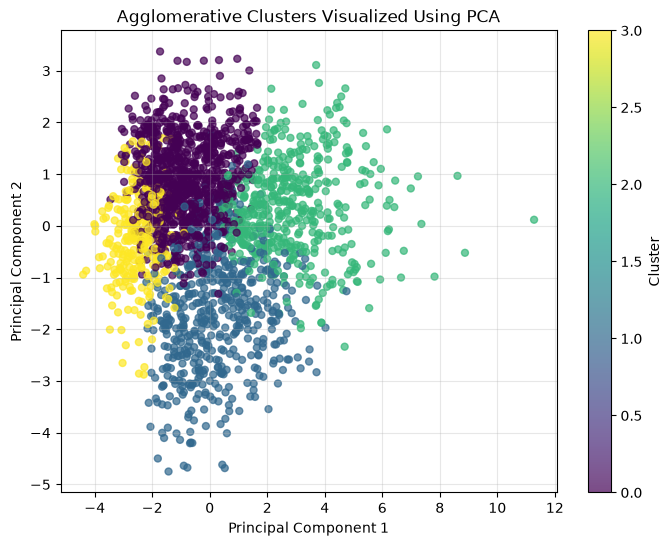

In [10]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=agg_labels,
    cmap="viridis",
    s=25,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Agglomerative Clusters Visualized Using PCA")
plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.3)
plt.show()

## Comparison of Clustering Algorithms

K-Means and Agglomerative Hierarchical Clustering are compared using the Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index. These internal metrics evaluate clustering structure without using the ground-truth tumor labels during model fitting.

In [11]:
clustering_results = pd.DataFrame({
    "Algorithm": ["K-Means", "Agglomerative Clustering"],
    "Silhouette Score": [
        kmeans_silhouette,
        agg_silhouette
    ],
    "Davies-Bouldin Index": [
        kmeans_davies_bouldin,
        agg_davies_bouldin
    ],
    "Calinski-Harabasz Index": [
        kmeans_calinski_harabasz,
        agg_calinski_harabasz
    ]
})

display(clustering_results.round(4))

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,0.2468,1.2790,798.4476
1,Agglomerative Clustering,0.2156,1.3366,693.3752


# Dendrogram for Agglomerative Hierarchical Clustering

A dendrogram visualizes the sequence in which observations or clusters are merged during hierarchical clustering. The vertical axis represents the linkage distance at which merges occur. A representative sample of 150 observations is used to produce a readable dendrogram; this visualization is separate from the Agglomerative model evaluated on the full dataset.

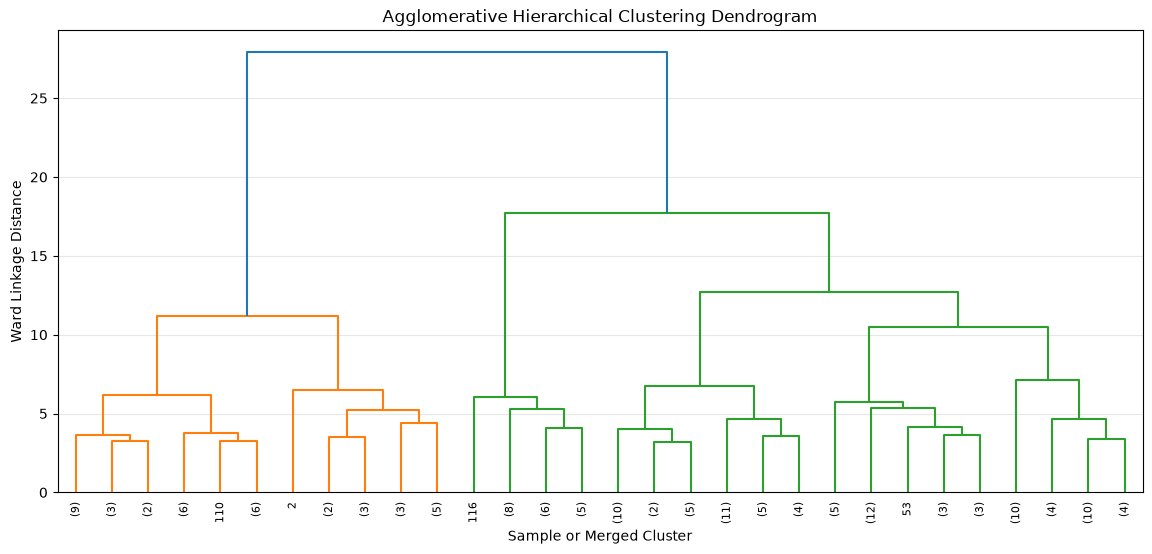

In [12]:
# Select a reproducible sample for visualization
rng = np.random.RandomState(42)
sample_indices = rng.choice(
    X_scaled.shape[0],
    size=150,
    replace=False
)

X_dendrogram = X_scaled[sample_indices]

# Ward linkage for hierarchical merging
linkage_matrix = linkage(
    X_dendrogram,
    method="ward"
)

plt.figure(figsize=(14, 6))
dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=8
)

plt.title("Agglomerative Hierarchical Clustering Dendrogram")
plt.xlabel("Sample or Merged Cluster")
plt.ylabel("Ward Linkage Distance")
plt.grid(axis="y", alpha=0.3)
plt.show()

# K-Means Visualization Using t-SNE

t-Distributed Stochastic Neighbor Embedding (t-SNE) is a nonlinear dimensionality-reduction technique that maps high-dimensional data into two dimensions while attempting to preserve local neighborhood relationships. The plot visualizes the K-Means cluster assignments in the resulting two-dimensional space. t-SNE is used only for visualization and does not affect the clustering model or its evaluation metrics.

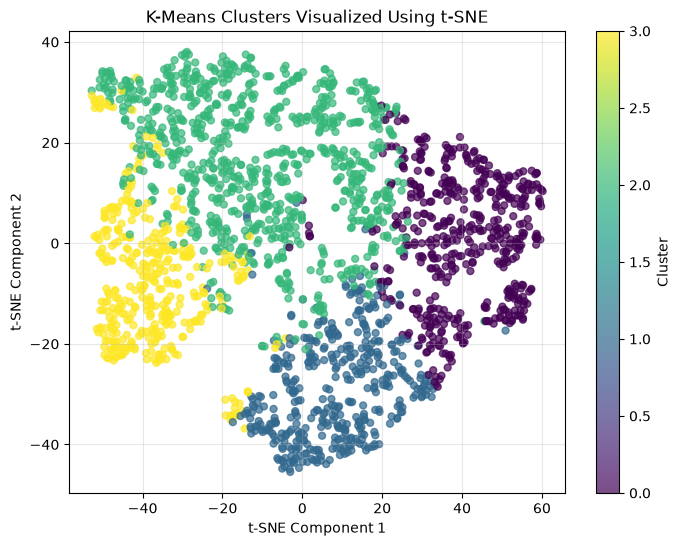

In [13]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=25,
    alpha=0.7
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("K-Means Clusters Visualized Using t-SNE")
plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.3)
plt.show()

# Conclusion

K-Means and Agglomerative Hierarchical Clustering were applied to the standardized numerical features of the brain tumor dataset using four clusters. Their performance was evaluated using the Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index.

K-Means achieved a Silhouette Score of 0.2468, a Davies–Bouldin Index of 1.2790, and a Calinski–Harabasz Index of 798.4476. Agglomerative Clustering achieved a Silhouette Score of 0.2156, a Davies–Bouldin Index of 1.3366, and a Calinski–Harabasz Index of 693.3752.

Based on these internal evaluation metrics, K-Means performed better than Agglomerative Clustering for this experiment. The PCA and t-SNE visualizations provide additional views of the cluster assignments, while the dendrogram illustrates the hierarchical merging process.

These results describe the structure of the feature space and do not establish that each cluster corresponds to a particular tumor type. The ground-truth tumor labels were kept separate from the clustering process and can be used afterward for interpretation.

## Post-Clustering Interpretation Using Ground-Truth Labels

The ground-truth tumor types are compared with the cluster assignments after fitting the clustering models. This analysis helps examine how the discovered clusters relate to the known tumor categories. The labels are not used to fit the models or calculate the internal clustering metrics.

In [14]:
# Compare K-Means clusters with actual tumor types
print("K-Means: Cluster vs Tumor Type")
display(pd.crosstab(
    pd.Series(kmeans_labels, name="K-Means Cluster"),
    y_true
))

# Compare Agglomerative clusters with actual tumor types
print("Agglomerative: Cluster vs Tumor Type")
display(pd.crosstab(
    pd.Series(agg_labels, name="Agglomerative Cluster"),
    y_true
))

K-Means: Cluster vs Tumor Type


tumor_type,Glioma,Meningioma,Pituitary tumor
K-Means Cluster,,,
0,149,256,92
1,161,220,48
2,191,207,486
3,53,25,304


Agglomerative: Cluster vs Tumor Type


tumor_type,Glioma,Meningioma,Pituitary tumor
Agglomerative Cluster,,,
0,199,156,558
1,191,290,59
2,135,241,90
3,29,21,223


## Interpretation of Cluster Composition

The cross-tabulation results show that both clustering algorithms identify groups with different distributions of the known tumor types. In K-Means, Cluster 3 contains 304 Pituitary tumor samples out of 382, while Cluster 2 contains 486 Pituitary tumor samples out of 884. In Agglomerative Clustering, Cluster 3 contains 223 Pituitary tumor samples out of 273, indicating a relatively concentrated distribution of this tumor type.

However, Glioma and Meningioma samples are distributed across multiple clusters. This suggests that the numerical features do not produce a complete separation of all three tumor types under these clustering configurations. These observations are for post-clustering interpretation only; the ground-truth labels were not used to fit the clustering algorithms.

## Comparison of Agglomerative Linkage Strategies

Agglomerative Hierarchical Clustering supports different linkage strategies that determine how the distance between clusters is measured. In this experiment, Ward, Complete, and Average linkage are compared using four clusters and the same standardized numerical features.

The Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index are used to evaluate each strategy. Ground-truth tumor labels are not used during model fitting or evaluation.

In [15]:
linkage_results = []

for method in ["ward", "complete", "average"]:
    model = AgglomerativeClustering(
        n_clusters=4,
        linkage=method
    )

    labels = model.fit_predict(X_scaled)

    linkage_results.append({
        "Linkage": method.capitalize(),
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(
            X_scaled, labels
        ),
        "Calinski-Harabasz Index": calinski_harabasz_score(
            X_scaled, labels
        )
    })

linkage_comparison = pd.DataFrame(linkage_results)

display(
    linkage_comparison.round(4).sort_values(
        by="Silhouette Score",
        ascending=False
    )
)

,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
2,Average,0.4279,0.7601,55.9395
0,Ward,0.2156,1.3366,693.3752
1,Complete,0.1982,1.3131,382.1469


## Linkage Strategy Comparison — Conclusion

Three linkage strategies were evaluated for Agglomerative Hierarchical Clustering using four clusters. Average linkage achieved the highest Silhouette Score (0.4279) and the lowest Davies–Bouldin Index (0.7601), indicating better separation and cohesion according to these two metrics. Ward linkage achieved the highest Calinski–Harabasz Index (693.3752), while Complete linkage did not achieve the best result on any of the three metrics.

The results demonstrate that the choice of linkage strategy affects clustering quality. Average linkage is preferable according to the Silhouette and Davies–Bouldin metrics in this experiment, whereas Ward linkage performs better according to the Calinski–Harabasz Index. The preferred strategy therefore depends on the evaluation criterion.